In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')


project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [60]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *

In [ ]:
# hacky fix for pickling issue
class AutocorrelationOnlyCritic(object):
    def __init__(self):
        pass


load_path = os.path.join(project_folder, 'analyses/architecture tests/saved/opticflow/autocorrelations only (1, 0, 1), hidden_dim:3, embed_dim:3, layers:2, iter:16 with pure.dat')
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

load_path_sh = os.path.join(project_folder, '/analyses/architecture tests/saved/opticflow/autocorrelations only (1, 0, 1), hidden_dim:3, embed_dim:3, layers:2, iter:16, shuffle_trial_per_time:True, with pure.dat')
with open(load_path_sh, 'rb') as f:
    data_dict_sh = pickle.load(f)
data_sh = Namespace(**data_dict_sh)

load_path_ctl = os.path.join(project_folder, '/analyses/noise correlations/saved/opticflow/trial shuffle comparisons (1, 0, 1) N=93 high-iter.dat')
with open(load_path_ctl, 'rb') as f:
    data_dict_ctl = pickle.load(f)
data_ctl = Namespace(**data_dict_ctl)

In [38]:
data_dict.keys()

dict_keys(['critic_type', 'critic_params_ctl', 'mi_measurement_params', 'mi_averages_test_ctl', 'V_E_buffer', 'mi_stdevs_test', 'mi_stdevs_test_ctl', 'V_width', 'mi_averages_train_ctl', 'mi_stdevs_train', 'mi_stdevs_train_ctl', 'critic_config', 'N_trials', 'E_width', 'mi_averages_test', 'opt_params', 'mi_averages_train', 'critic_params'])

In [39]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    full_stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, full_stdevs

In [40]:
average_test, stdevs_test = process_trials(data.mi_averages_test, data.mi_stdevs_test)
average_test_sh, stdevs_test_sh = process_trials(data_sh.mi_averages_test, data_sh.mi_stdevs_test)
average_test_ctl, stdevs_test_ctl = process_trials(data_ctl.mi_averages_test['control'], data_ctl.mi_stdevs_test['control'])

Text(0.5, 1.0, 'Predictive information in\n neuron-neuron correlations')

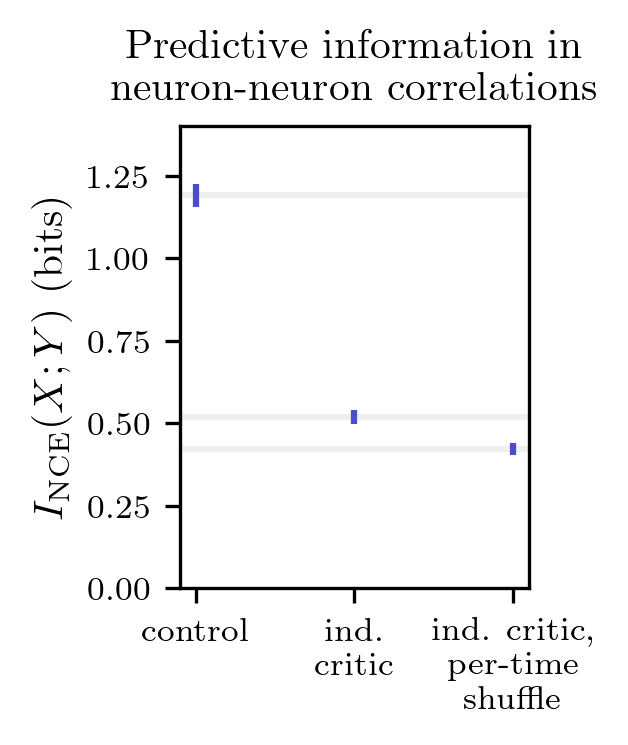

In [ ]:
c1 = 0.3
c2 = 0.8
alp = 0.3
fig, ax = plt.subplots(dpi=300, figsize=[3*plot_scale, 4*plot_scale])

show_train = False

x = np.arange(3)

y = average_test_ctl / np.log(2)
yerr = stdevs_test_ctl / np.log(2)
ax.errorbar(x[0], y, yerr, marker='', color=(c1,c1,c2), zorder=2)
ax.axhline(y, color=(c2,c2,c2,alp), zorder=1)

y = average_test / np.log(2)
yerr = stdevs_test / np.log(2)
ax.errorbar(x[1], y, yerr, marker='', color=(c1,c1,c2), zorder=2)
ax.axhline(y, color=(c2,c2,c2,alp), zorder=1)

y = average_test_sh / np.log(2)
yerr = stdevs_test_sh / np.log(2)
ax.errorbar(x[2], y, yerr, marker='', color=(c1,c1,c2), zorder=2)
ax.axhline(y, color=(c2,c2,c2,alp), zorder=1)




ax.set_xticks(x)
ax.set_ylim(0,1.4)
ax.set_ylim(0)
ax.set_xticklabels(["control", "ind.\n critic", "ind. critic, \n per-time\n shuffle"])
ax.set_ylabel("$I_{\mathrm{NCE}}(X;Y)$ (bits)")
ax.set_title("Predictive information in\n neuron-neuron correlations") 
# plt.savefig('./plots/independent critic ansatz.png', dpi=3000)

## $\tau$ = 100

In [43]:
# stim = 'opticflow'
# setup = (1,0,1)
# N_neurons = 93
# V_width, V_E_buffer, E_width = setup

In [ ]:
load_path = os.path.join(project_folder, '/analyses/architecture tests/saved/opticflow/autocorrelations only (1, 0, 1), hidden_dim:3, embed_dim:3, layers:2, iter:16 with pure.dat')
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

# load_path = os.path.join(project_folder, '/analyses/architecture tests/saved/opticflow/autocorrelations only (1, 5, 1), hidden_dim:3, embed_dim:3, layers:2, iter:16, shuffle_trial_per_time:False, with pure.dat'
# with open(load_path, 'rb') as f:
#     data_dict = pickle.load(f)
# data = Namespace(**data_dict)

In [63]:
average_test, stdevs_test = process_trials(data.mi_averages_test, data.mi_stdevs_test)
average_train, stdevs_train = process_trials(data.mi_averages_train, data.mi_stdevs_train)
average_test_ctl, stdevs_test_ctl = process_trials(data.mi_averages_test_ctl, data.mi_stdevs_test_ctl)
average_train_ctl, stdevs_train_ctl = process_trials(data.mi_averages_train_ctl, data.mi_stdevs_train_ctl)

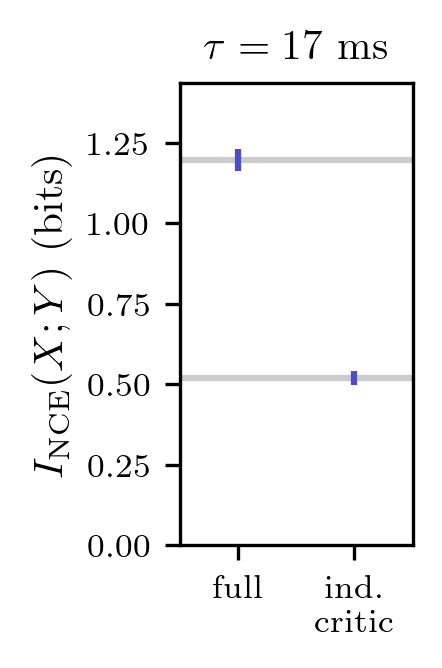

In [68]:
c1 = 0.3
c2 = 0.8
alp = 1
fig, ax = plt.subplots(dpi=300, figsize=[2*plot_scale, 4*plot_scale])


x = np.arange(2)

y = average_test_ctl / np.log(2)
ymax = y
yerr = stdevs_test_ctl / np.log(2)
ax.errorbar(x[0], y, yerr, marker='', color=(c1,c1,c2), zorder=2)
ax.axhline(y, color=(c2,c2,c2,alp), zorder=1)

y = average_test / np.log(2)
yerr = stdevs_test / np.log(2)
ax.errorbar(x[1], y, yerr, marker='', color=(c1,c1,c2), zorder=2)
ax.axhline(y, color=(c2,c2,c2,alp), zorder=1)


tau = round((data.V_width + data.V_E_buffer) / 60 * 1000)

ax.set_xticks(x)
ax.set_xlim(-0.5,1.5)
ax.set_ylim(0,1.2 * ymax)
ax.set_ylim(0)
# ax.set_xticklabels(trial_keys)
ax.set_xticklabels(["full", "ind.\n critic"])
ax.set_ylabel("$I_{\mathrm{NCE}}(X;Y)$ (bits)")
ax.set_title(f"$\\tau = {tau:.0f}$ ms") 
plt.savefig(f'./plots/independent critic simple tau = {tau}.png', dpi=3000)
